In [64]:
import pandas as pd
import pickle


In [65]:
df=pd.read_csv(r"D:\datads\youtube_ad_revenue_dataset (6).csv")
df

,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,vid_3092,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,vid_3459,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,vid_4784,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,vid_4078,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,vid_3522,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388
...,...,...,...,...,...,...,...,...,...,...,...,...
122395,vid_2902,2024-12-14 10:50:40.993199,9853,1673.0,147.0,42075.704885,25.490195,210818,Education,Tablet,US,280.986396
122396,vid_3890,2024-07-13 10:50:40.993199,10128,1709.0,63.0,57563.703040,16.229133,878860,Music,Desktop,UK,354.612981
122397,vid_3934,2024-06-10 10:50:40.993199,10267,700.0,NaN,27549.714659,23.822365,576756,Tech,Tablet,CA,203.643106
122398,vid_4260,2024-12-22 10:50:40.993199,10240,1616.0,106.0,56967.384382,7.753099,585138,Music,Mobile,UK,351.525811


In [33]:
df.columns

Index(['video_id', 'date', 'views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers', 'category', 'device', 'country',
       'ad_revenue_usd'],
      dtype='object')

In [34]:
df.drop(['video_id'],axis=1)

,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388
...,...,...,...,...,...,...,...,...,...,...,...
122395,2024-12-14 10:50:40.993199,9853,1673.0,147.0,42075.704885,25.490195,210818,Education,Tablet,US,280.986396
122396,2024-07-13 10:50:40.993199,10128,1709.0,63.0,57563.703040,16.229133,878860,Music,Desktop,UK,354.612981
122397,2024-06-10 10:50:40.993199,10267,700.0,NaN,27549.714659,23.822365,576756,Tech,Tablet,CA,203.643106
122398,2024-12-22 10:50:40.993199,10240,1616.0,106.0,56967.384382,7.753099,585138,Music,Mobile,UK,351.525811


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122400 entries, 0 to 122399
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   video_id              122400 non-null  object 
 1   date                  122400 non-null  object 
 2   views                 122400 non-null  int64  
 3   likes                 116283 non-null  float64
 4   comments              116288 non-null  float64
 5   watch_time_minutes    116295 non-null  float64
 6   video_length_minutes  122400 non-null  float64
 7   subscribers           122400 non-null  int64  
 8   category              122400 non-null  object 
 9   device                122400 non-null  object 
 10  country               122400 non-null  object 
 11  ad_revenue_usd        122400 non-null  float64
dtypes: float64(5), int64(2), object(5)
memory usage: 11.2+ MB


In [36]:
df.isnull().any()

video_id                False
date                    False
views                   False
likes                    True
comments                 True
watch_time_minutes       True
video_length_minutes    False
subscribers             False
category                False
device                  False
country                 False
ad_revenue_usd          False
dtype: bool

In [67]:
print(df.isnull().sum())

video_id                   0
date                       0
views                      0
likes                   6117
comments                6112
watch_time_minutes      6105
video_length_minutes       0
subscribers                0
category                   0
device                     0
country                    0
ad_revenue_usd             0
dtype: int64


In [68]:
df.shape

(122400, 12)

In [69]:
# null value columns --likes,comments,watch_time_minutes all are numeric columns



In [71]:
df['likes'].dtypes

dtype('float64')

In [72]:
df['watch_time_minutes'].dtypes

dtype('float64')

In [73]:
df['comments'].dtypes

dtype('float64')

# spliting the dataset into  feature and columns

In [74]:
X=df.drop(['ad_revenue_usd'],axis=1)
y=df['ad_revenue_usd']

print(X.shape)
print("__________________________________________________________________")
print(y.shape)
print("___________________________________________________________________________")

print (X.columns)
print("_______________________________________________________________________________")
print(y)

(122400, 11)
__________________________________________________________________
(122400,)
___________________________________________________________________________
Index(['video_id', 'date', 'views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers', 'category', 'device', 'country'],
      dtype='object')
_______________________________________________________________________________
0         203.178237
1         140.880508
2         360.134008
3         224.638261
4         165.514388
             ...    
122395    280.986396
122396    354.612981
122397    203.643106
122398    351.525811
122399    253.842824
Name: ad_revenue_usd, Length: 122400, dtype: float64


# spliting the dataset into numeric and catgorical


In [75]:
numeric = X.select_dtypes(include=['int64','float64']).columns
catgorical = X.select_dtypes(include =['object']).columns

print(numeric)
print("__________________________________________________________________")
print(catgorical)

Index(['views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers'],
      dtype='object')
__________________________________________________________________
Index(['video_id', 'date', 'category', 'device', 'country'], dtype='object')


# datavisuvalisation on null value columns

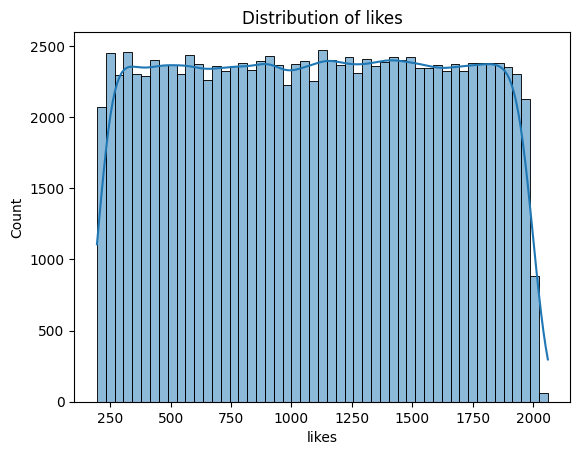

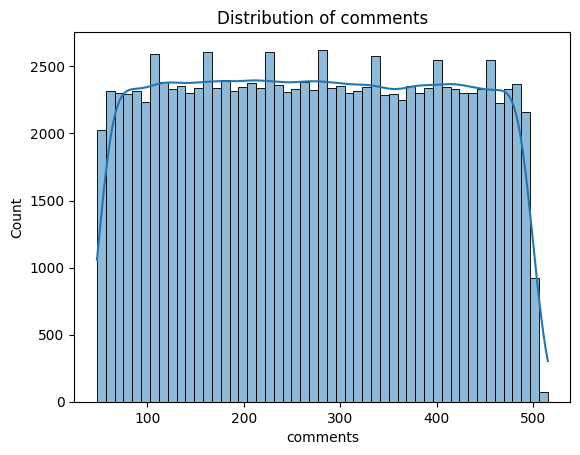

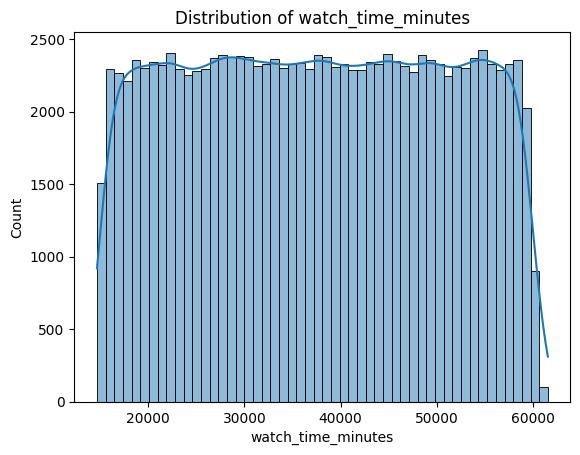

In [76]:

import seaborn as sns
import matplotlib.pyplot as plt

cols = ['likes', 'comments', 'watch_time_minutes']

for col in cols:
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

In [47]:
print("skew value for like",df['likes'].skew())
print("kurt value for like",df['likes'].kurt())

skew value for like -0.0027579035972128923
kurt value for like -1.1962956704335688


In [84]:

df['likes'].fillna(df['likes'].mean(),inplace = True)

In [85]:
print("skew value for comments ",df['comments'].skew())
print("kurt value for comments ",df['comments'].kurt())

skew value for comments  0.00793582575228909
kurt value for comments  -1.0982323077133385


In [87]:
df['comments'].fillna(df['comments'].mean(),inplace = True)

In [88]:
print("skew value for watch_time_minutes ",df['watch_time_minutes'].skew())
print("kurt value for watch_time_minutes ",df['watch_time_minutes'].kurt())

skew value for watch_time_minutes  0.0009027191329527335
kurt value for watch_time_minutes  -1.1944357188536434


In [89]:
df['watch_time_minutes'].fillna(df['watch_time_minutes'].mean(),inplace = True)

In [90]:
df.isnull().sum()

video_id                0
date                    0
views                   0
likes                   0
comments                0
watch_time_minutes      0
video_length_minutes    0
subscribers             0
category                0
device                  0
country                 0
ad_revenue_usd          0
dtype: int64

# checking the duplicates

In [91]:
print(df.duplicated().any())
print(df.duplicated().sum())

True
2400


In [92]:
df.drop_duplicates(inplace= True)

In [93]:

print(df.duplicated().sum())

0


# checking the outliers

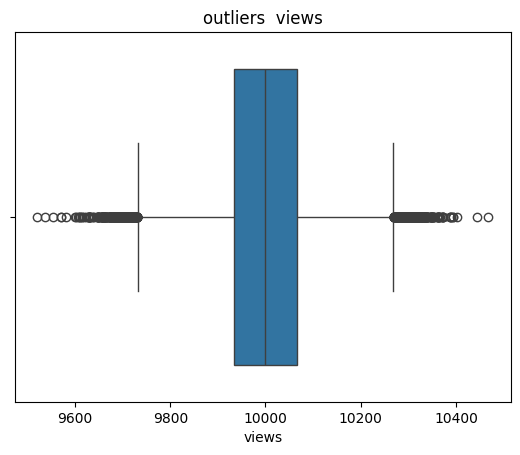

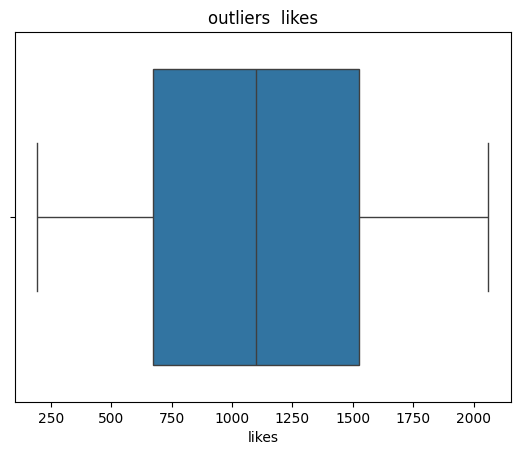

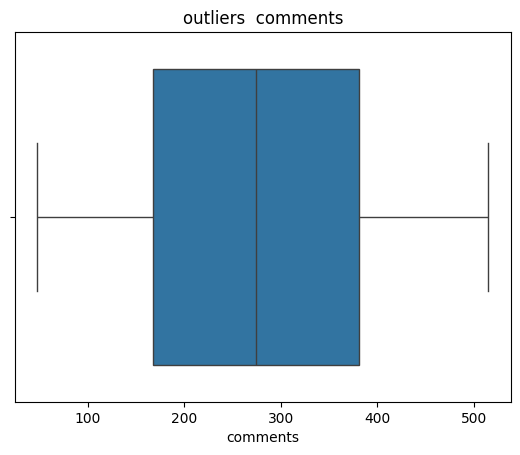

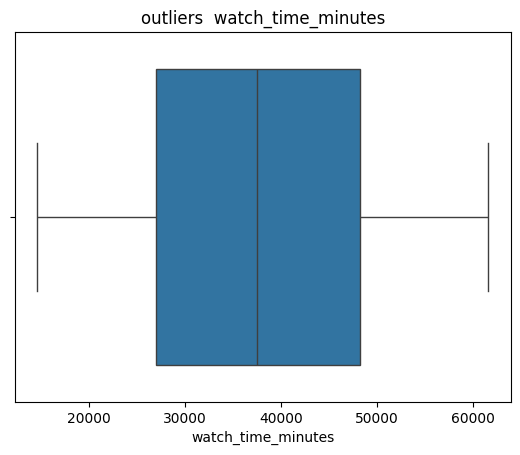

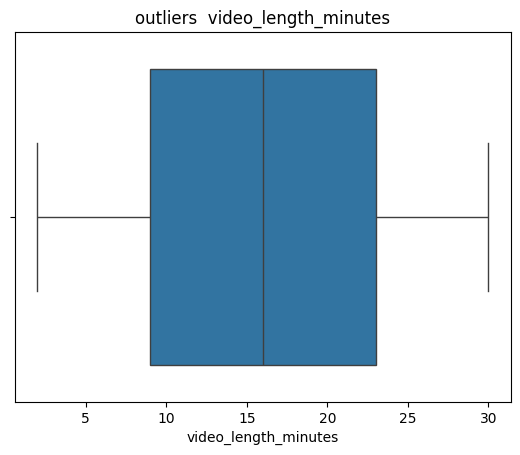

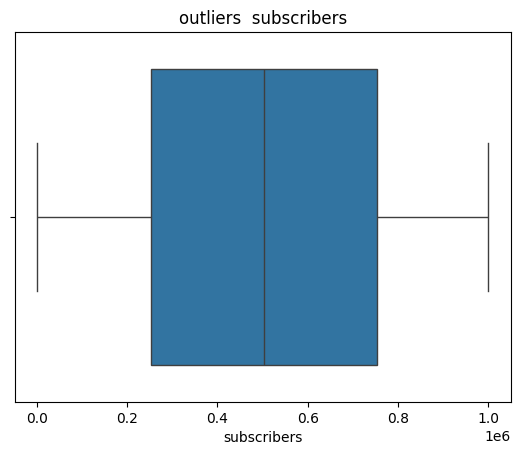

In [94]:
numeric = X.select_dtypes(include=['int64','float64']).columns

import seaborn as sns
import matplotlib.pyplot as plt


for col in numeric:
    sns.boxplot(x=df[col])
    plt.title(f'outliers  {col}')
    plt.show()


In [95]:
df['views'].skew()

np.float64(-0.0029119685491647124)

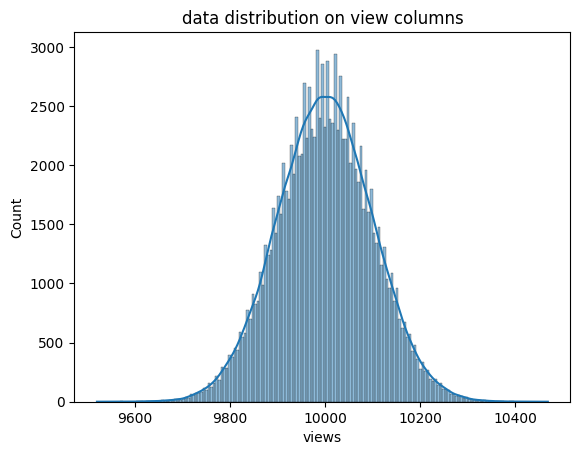

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['views'],kde =True)
plt.title("data distribution on view columns")
plt.show()



In [96]:
import numpy as np
mean_view = df['views'].mean()
std_view = df['views'].std()
z_score = (df['views']-mean_view)/std_view
df_clean = df[np.abs(z_score)<=3]

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (120000, 12)
Cleaned shape: (119684, 12)


# feather enginering 

In [97]:
df['like_rate'] = df['likes'] / (df['views']+1)
df['comment_rate'] = df['comments'] / (df['views']+1)
df['engagement_rate'] = (df['likes'] + df['comments']) / (df['views']+1)

df['revenue_per_view'] = df['ad_revenue_usd'] / (df['views']+1)
df['revenue_per_minute'] = df['ad_revenue_usd'] / (df['watch_time_minutes']+1)
df['likes_per_subscriber'] = df['likes'] / df['subscribers']
df['comments_per_subscriber'] = df['comments'] / df['subscribers']
df['views_pdf.er_subscriber'] = df['views'] / df['subscribers']

df.head()

,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd,like_rate,comment_rate,engagement_rate,revenue_per_view,revenue_per_minute,likes_per_subscriber,comments_per_subscriber,views_pdf.er_subscriber
0,vid_3092,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237,0.122874,0.032203,0.155077,0.020447,0.007668,0.005353,0.001403,0.043563
1,vid_3459,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508,0.064085,0.034538,0.098622,0.014063,0.009262,0.000872,0.000470,0.013610
2,vid_4784,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008,0.195979,0.018519,0.214498,0.035664,0.006281,0.008228,0.000777,0.041977
3,vid_4078,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261,0.118685,0.024116,0.142800,0.022385,0.007169,0.002741,0.000557,0.023094
4,vid_3522,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388,0.187867,0.048231,0.236097,0.016736,0.010565,0.044207,0.011349,0.235284


In [98]:
print(df.columns)

df.columns = df.columns.str.strip()

df['date'] = pd.to_datetime(df['date'], errors='coerce')

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['dayofweek'] = df['date'].dt.dayofweek

df.drop('date', axis=1, inplace=True)

Index(['video_id', 'date', 'views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers', 'category', 'device', 'country',
       'ad_revenue_usd', 'like_rate', 'comment_rate', 'engagement_rate',
       'revenue_per_view', 'revenue_per_minute', 'likes_per_subscriber',
       'comments_per_subscriber', 'views_pdf.er_subscriber'],
      dtype='object')


# groupby 

In [99]:
df.groupby('category')[['views','likes','comments']].mean()



,views,likes,comments
category,,,
Education,9999.914078,1099.976182,275.750415
Entertainment,10000.106367,1096.888268,272.799917
Gaming,9999.773706,1104.980102,274.434101
Lifestyle,9999.808137,1093.727599,274.077691
Music,10000.379915,1101.692140,274.428432
Tech,9999.009986,1100.197850,274.612420


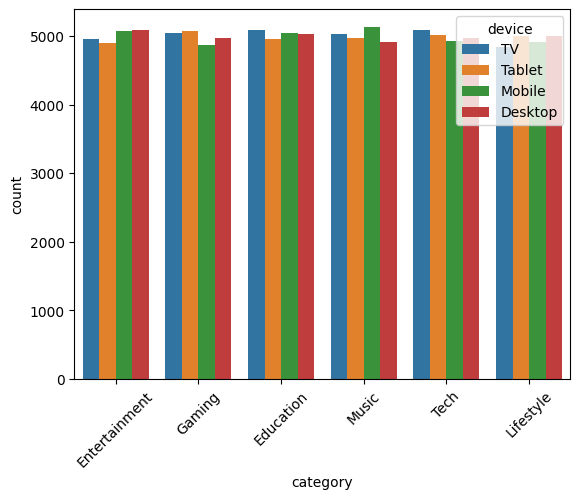

In [43]:
sns.countplot(x='category', hue='device', data=df)
plt.xticks(rotation=45)
plt.show()

In [44]:
df.groupby ('device')[['views','likes','comments']].mean()

,views,likes,comments
device,,,
Desktop,10000.599019,1092.718968,274.577383
Mobile,10000.172297,1100.545784,273.613583
TV,9999.290268,1103.131652,274.655236
Tablet,9999.268728,1101.944650,274.561918


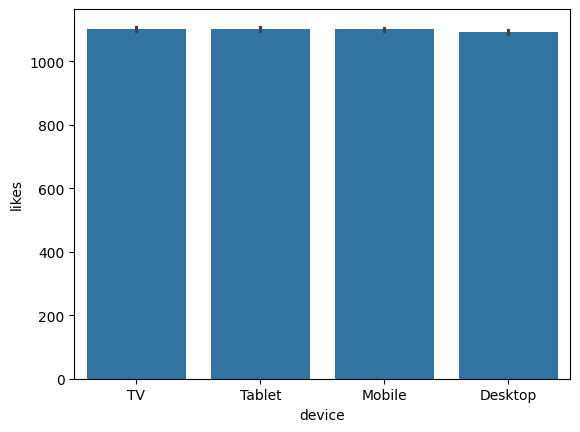

In [100]:
sns.barplot(x='device',y='likes', data=df)
plt.show()


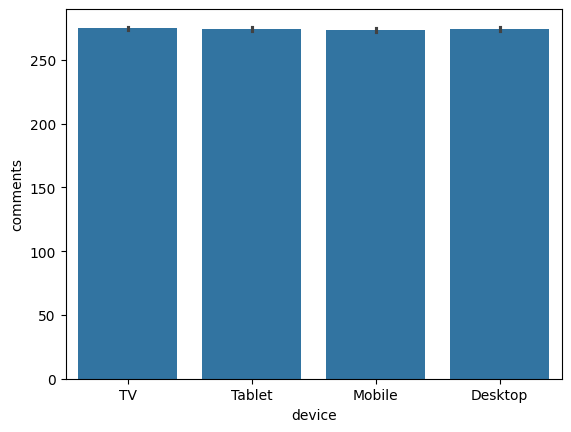

In [101]:
sns.barplot(x='device',y='comments', data=df)
plt.show()


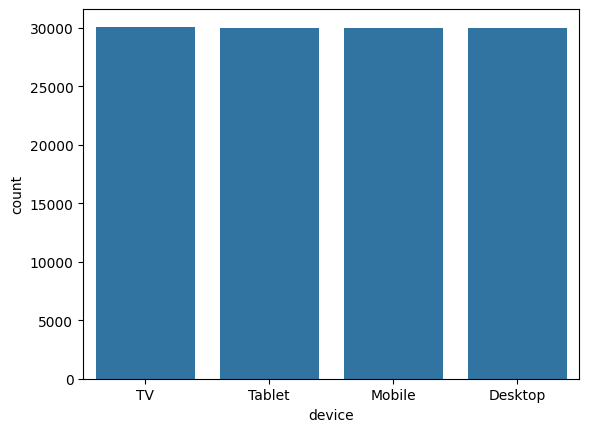

In [102]:

sns.countplot(x='device', data=df)
plt.show()

In [103]:
df.groupby('country')[['views','likes','comments']].mean()


,views,likes,comments
country,,,
AU,10000.029582,1099.182681,273.930593
CA,9999.720418,1102.395255,274.524666
DE,9999.821032,1098.018728,274.404246
IN,10000.251935,1098.217947,275.328529
UK,9998.633992,1104.509666,274.361126
US,10000.540697,1095.149970,273.539441


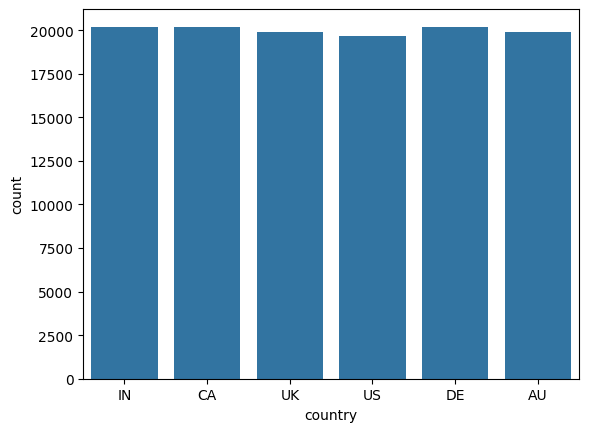

In [50]:
sns.countplot(x='country', data=df)
plt.show()

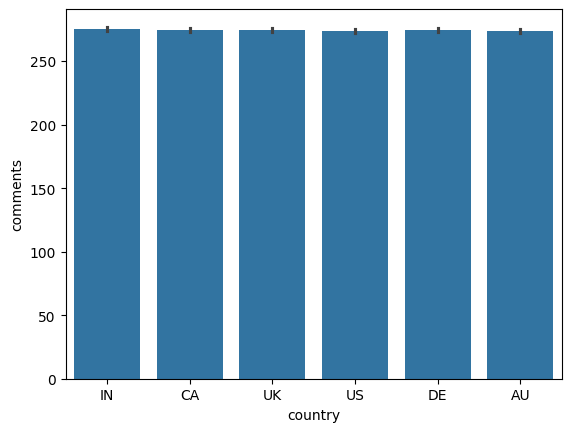

In [105]:
sns.barplot(x='country', y='comments', data=df)
plt.show()

# spliting the dataset into train_test _split

In [106]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size =0.2)

# encoding


In [107]:
from sklearn .preprocessing import  StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric = X.select_dtypes(include=['int64','float64']).columns
catgorical = X.select_dtypes(include =['object']).columns


preprocessing = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numeric),
        ("cat",OneHotEncoder(handle_unknown="ignore",),catgorical)

        
    ]
    )

X_train_enc = preprocessing.fit_transform(X_train)
X_test_enc = preprocessing.fit_transform(X_test)

In [109]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate numeric and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns


num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder())
])


preprocessing = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)

    ]
)
X_train_enc = preprocessing.fit_transform(X_train)
X_test_enc = preprocessing.transform(X_test)

# regression 

In [58]:
# 
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

linear = LinearRegression()
linear.fit(X_train_enc,y_train)

train_predict = linear.predict(X_train_enc)
test_predict = linear.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.95024913789352
rmse 13.8142032939038
 mae 3.655586058442925
**********test************
r2 0.9510604537091444
rmse 13.725191206766421
 mae 3.592950594023566


In [60]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

lasso = Lasso()
lasso.fit(X_train_enc,y_train)

train_predict = lasso.predict(X_train_enc)
test_predict = lasso.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9491848696295212
rmse 13.961177850855927
 mae 4.4472318064829155
**********test************
r2 0.9502735222630861
rmse 13.835099376534037
 mae 4.377919952341634


In [59]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

ridge= Ridge()
ridge.fit(X_train_enc,y_train)

train_predict = ridge.predict(X_train_enc)
test_predict = ridge.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9502486023779021
rmse 13.8142776413763
 mae 3.6521254000120846
**********test************
r2 0.9510639579659419
rmse 13.72469981014309
 mae 3.5881329558714854


In [61]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

dt= DecisionTreeRegressor()
dt.fit(X_train_enc,y_train)

train_predict = dt.predict(X_train_enc)
test_predict = dt.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 1.0
rmse 7.708758063337559e-09
 mae 3.5429704776381446e-11
**********test************
r2 0.9091352985271913
rmse 18.701913157549132
 mae 5.156285438475783


In [110]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

rf= RandomForestRegressor( n_estimators=10,random_state=42)
rf.fit(X_train_enc,y_train)

train_predict = rf.predict(X_train_enc)
test_predict = rf.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9903084778537606
rmse 6.101815939074456
 mae 1.5673975292482243
**********test************
r2 0.9455765349993311
rmse 14.429929996012023
 mae 3.945306772909409


In [117]:
scores = {
    "linearRegression": 0.9510604537091444,
    "lasso": 0.9502735222630861,
    "ridge": 0.9510639579659419,
    "DecisionTreeRegressor": 0.9101011494858107,
    "randomforestregression": 0.9455765349993311
}

# Best model
best_model_name = max(scores, key=scores.get)

print("Best Model:", best_model_name)
print("Best Score:", scores[best_model_name])


"""best_model = max(scores, key=scores.get)

print("\nBest Model:", best_model)
print("Best Score:", scores[best_model])"""

# taking the r2_test values

Best Model: ridge
Best Score: 0.9510639579659419


'best_model = max(scores, key=scores.get)\n\nprint("\nBest Model:", best_model)\nprint("Best Score:", scores[best_model])'

In [120]:
#Save the Best Model
models = {
    "linearRegression": lr,
    "lasso": lasso,
    "ridge": ridge,
    "DecisionTreeRegressor": dt,
    "randomforestregression": rf
}
best_model = models[best_model_name]

import pickle

with open("model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

NameError: name 'lr' is not defined

In [ ]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import pickle


df=pd.read_csv(r"D:\datads\youtube_ad_revenue_dataset (6).csv")
df

X=df.drop(['ad_revenue_usd'],axis=1)
y=df['ad_revenue_usd']

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size =0.2)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate numeric and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns


num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder())
])


preprocessing = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)

    ]
)
X_train_enc = preprocessing.fit_transform(X_train)
X_test_enc = preprocessing.transform(X_test)

# Create models
lr = LinearRegression()
lasso = Lasso()
ridge = Ridge()
dt = DecisionTreeRegressor()
rf = RandomForestRegressor()

# Train models
lr.fit(X_train_enc, y_train)
lasso.fit(X_train_enc, y_train)
ridge.fit(X_train_enc, y_train)
dt.fit(X_train_enc, y_train)
rf.fit(X_train_enc, y_train)
models = {
    "linearRegression": lr,
    "lasso": lasso,
    "ridge": ridge,
    "DecisionTreeRegressor": dt,
    "randomforestregression": rf
}
best_model = models[best_model_name]

import pickle

with open("model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

In [ ]:
# bullding the app

with open("model.pkl", "rb") as file:
    model = pickle.load(file)